Total fields: 1206 | unique IDs: 1206

== Summary ==
                                   0
Total fields                    1206
Countries                          2
Crops                              3
Years                      2017-2024
Blocks                            76
Mean season length (days)      158.2

== By country ==
           fields   pct
country                
Argentina     665  55.1
Brazil        541  44.9

== By crop ==
         fields   pct
crop                 
Soybean     698  57.9
Wheat       258  21.4
Corn        250  20.7

== Crop x Country ==
country  Argentina  Brazil   All
crop                            
Corn           134     116   250
Soybean        409     289   698
Wheat          122     136   258
All            665     541  1206

== Year x Country ==
country  Argentina  Brazil   All
year                            
2017            22      56    78
2018            47      81   128
2019            50      86   136
2020           115      66   181
2021     

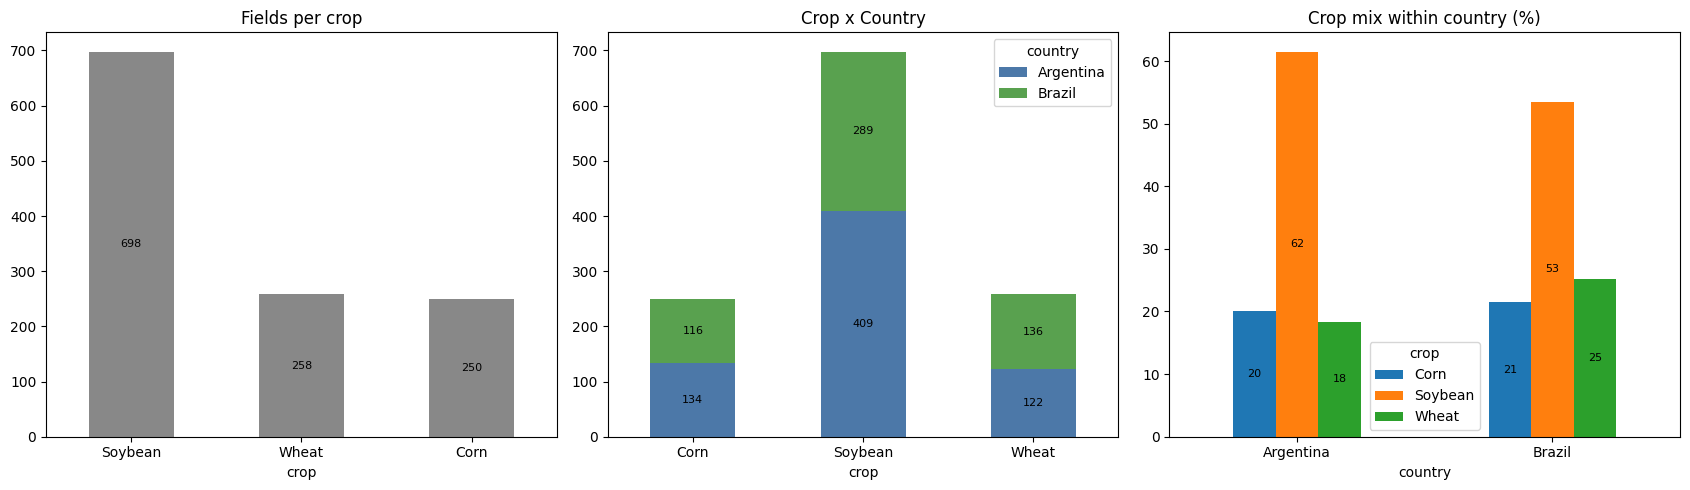


== Country summary ==
           fields  blocks  mean_lat  min_lat  max_lat  min_lon  max_lon  \
country                                                                   
Argentina     665      69    -33.49   -36.31   -24.85   -64.37   -59.72   
Brazil        541       7    -23.94   -24.12   -23.04   -49.45   -48.53   

           mean_season_days  pct_of_total  
country                                    
Argentina            168.29          55.1  
Brazil               145.85          44.9  

== Crop mix pct by country ==
country  Argentina  Brazil
crop                      
Corn          20.2    21.4
Soybean       61.5    53.4
Wheat         18.3    25.1

== Fields per block ==
           count  mean   std  min   25%   50%    75%    max
country                                                    
Argentina   69.0   9.6  15.5  1.0   2.0   4.0   11.0  107.0
Brazil       7.0  77.3  77.2  3.0  13.0  47.0  133.0  199.0

Top 5 blocks:
 block
Brazil_2        199
Brazil_0        133
Brazil_1

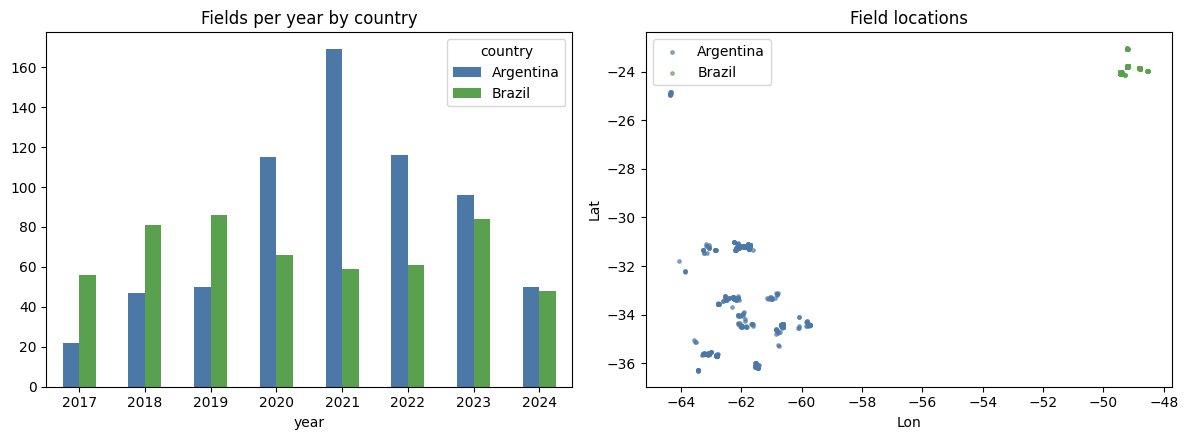


== Season x Country ==
country                     Argentina  Brazil   All
season                                             
Second crop (sown Jan-Mar)         12      73    85
Summer (sown Sep-Dec)             531     332   863
Winter (sown Apr-Jul)             122     136   258
All                               665     541  1206

== Season x Crop ==
crop                        Corn  Soybean  Wheat   All
season                                                
Second crop (sown Jan-Mar)    84        1      0    85
Summer (sown Sep-Dec)        166      697      0   863
Winter (sown Apr-Jul)          0        0    258   258
All                          250      698    258  1206

== Sowing month ==
country Argentina               Brazil              
crop         Corn Soybean Wheat   Corn Soybean Wheat
sowing                                              
1              11       1     0     22       0     0
2               0       0     0     45       0     0
3               0       0   

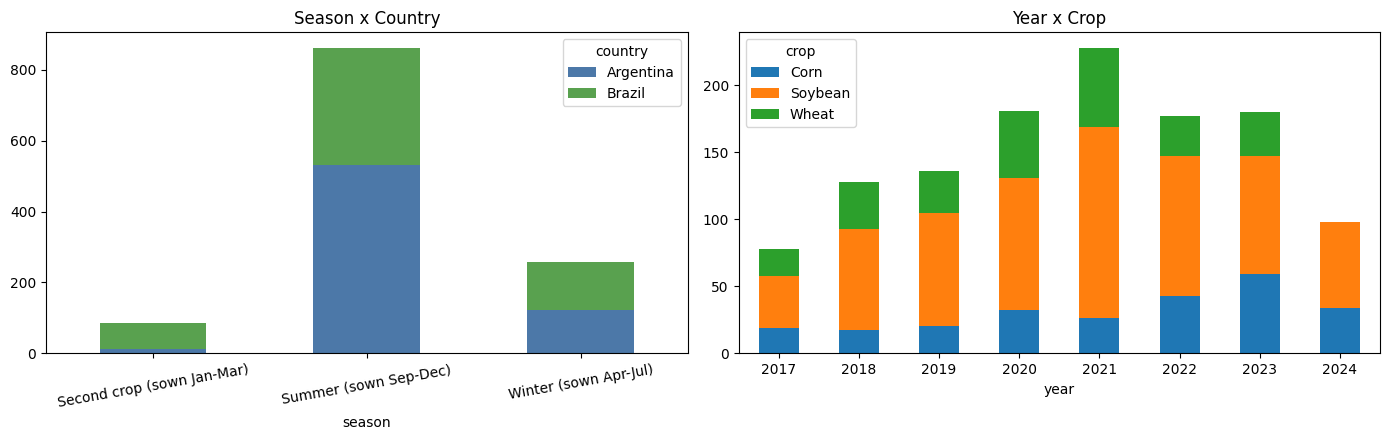


== Imbalance ratios ==
                                  value
Argentina / Brazil fields          1.23
Largest crop / smallest crop       2.79
Argentina blocks / Brazil blocks   9.86
Largest year / smallest year       2.92
Summer-sown share (%)             71.60

== Fold x Country ==
      Argentina  Brazil   All  blocks
fold                                 
0           123     199   322    14.0
1           127     133   260    14.0
2           128     133   261    17.0
3           161      29   190    16.0
4           126      47   173    15.0
All         665     541  1206     NaN

== Fold x Crop ==
crop  Corn  Soybean  Wheat   All
fold                            
0       81      176     65   322
1       48      152     60   260
2       50      151     60   261
3       39      110     41   190
4       32      109     32   173
All    250      698    258  1206


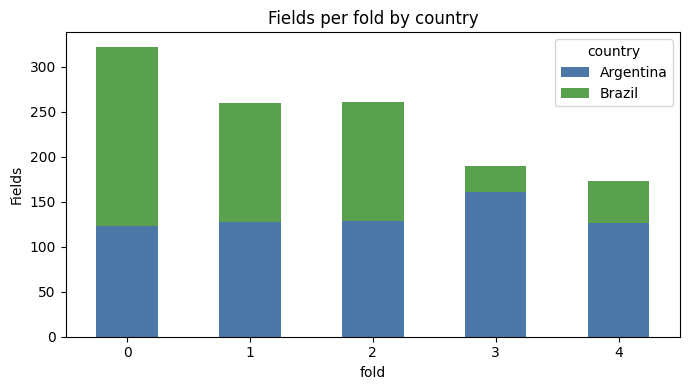

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Done. Files in: outputs


In [5]:
MASTER = "master_table.csv"
FOLDS  = "folds.csv"

import os, pandas as pd, numpy as np, matplotlib.pyplot as plt

OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
col = {"Argentina": "#4C78A8", "Brazil": "#59A14F"}
writer = pd.ExcelWriter(f"{OUT}/dataset_statistics.xlsx")
def save(t, name):
    t.to_excel(writer, sheet_name=name[:31]); print(f"\n== {name} ==\n{t}")

# ---- Load & prepare ----
df = pd.read_csv(MASTER, parse_dates=["sowing", "harvest"])
df = df.merge(pd.read_csv(FOLDS)[["field_id", "fold"]], on="field_id", how="left")
df["crop"] = df["label"].str.capitalize()
df["season_len_days"] = (df["harvest"] - df["sowing"]).dt.days
sm = df["sowing"].dt.month
df["season"] = np.select(
    [sm.isin([9, 10, 11, 12]), sm.isin([1, 2, 3]), sm.isin([4, 5, 6, 7])],
    ["Summer (sown Sep-Dec)", "Second crop (sown Jan-Mar)", "Winter (sown Apr-Jul)"], default="Other")
vc = df.country.value_counts()

# ================= 1. FINAL DATASET STATISTICS =================
print("Total fields:", len(df), "| unique IDs:", df.field_id.nunique())
save(pd.DataFrame({"Total fields": [len(df)], "Countries": [df.country.nunique()], "Crops": [df.crop.nunique()],
                   "Years": [f"{df.year.min()}-{df.year.max()}"], "Blocks": [df.block.nunique()],
                   "Mean season length (days)": [round(df.season_len_days.mean(), 1)]}).T, "Summary")
save(df.country.value_counts().to_frame("fields").assign(pct=lambda x: (x.fields/len(df)*100).round(1)), "By country")
save(df.crop.value_counts().to_frame("fields").assign(pct=lambda x: (x.fields/len(df)*100).round(1)), "By crop")
save(pd.crosstab(df.crop, df.country, margins=True), "Crop x Country")
save(pd.crosstab(df.year, df.country, margins=True), "Year x Country")
save(pd.crosstab(df.year, df.crop, margins=True), "Year x Crop")

# ================= 2. CROP-WISE GRAPHS =================
ct = pd.crosstab(df.crop, df.country)
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
df.crop.value_counts().plot.bar(ax=ax[0], color="#888", rot=0); ax[0].set_title("Fields per crop")
ct.plot.bar(stacked=True, ax=ax[1], color=[col[k] for k in ct.columns], rot=0); ax[1].set_title("Crop x Country")
(ct/ct.sum()*100).T.plot.bar(ax=ax[2], rot=0); ax[2].set_title("Crop mix within country (%)")
for a in ax:
    for p in a.patches:
        if p.get_height() > 0:
            a.annotate(round(p.get_height()), (p.get_x()+p.get_width()/2, p.get_y()+p.get_height()/2),
                       ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_crop_distribution.png", dpi=200); plt.show()

# ================= 3. ARGENTINA vs BRAZIL =================
cc = df.groupby("country").agg(fields=("field_id", "count"), blocks=("block", "nunique"),
        mean_lat=("lat", "mean"), min_lat=("lat", "min"), max_lat=("lat", "max"),
        min_lon=("lon", "min"), max_lon=("lon", "max"),
        mean_season_days=("season_len_days", "mean")).round(2)
cc["pct_of_total"] = (cc.fields/len(df)*100).round(1)
save(cc, "Country summary")
save((pd.crosstab(df.crop, df.country, normalize="columns")*100).round(1), "Crop mix pct by country")
bl = df.groupby(["country", "block"]).size().reset_index(name="n")
save(bl.groupby("country").n.describe().round(1), "Fields per block")
top = df.block.value_counts()
print("\nTop 5 blocks:\n", top.head(5), "\nShare of dataset in top 5 blocks: %.1f%%" % (top.head(5).sum()/len(df)*100))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pd.crosstab(df.year, df.country).plot.bar(ax=ax[0], color=[col["Argentina"], col["Brazil"]], rot=0)
ax[0].set_title("Fields per year by country")
for k, g in df.groupby("country"):
    ax[1].scatter(g.lon, g.lat, s=6, label=k, color=col[k], alpha=.6)
ax[1].set_title("Field locations"); ax[1].set_xlabel("Lon"); ax[1].set_ylabel("Lat"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_country_year_map.png", dpi=200); plt.show()

# ================= 4. SEASONAL & COUNTRY IMBALANCE =================
save(pd.crosstab(df.season, df.country, margins=True), "Season x Country")
save(pd.crosstab(df.season, df.crop, margins=True), "Season x Crop")
save(pd.crosstab(df.sowing.dt.month, [df.country, df.crop]), "Sowing month")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
pd.crosstab(df.season, df.country).plot.bar(stacked=True, ax=ax[0],
        color=[col["Argentina"], col["Brazil"]], rot=10); ax[0].set_title("Season x Country")
pd.crosstab(df.year, df.crop).plot.bar(stacked=True, ax=ax[1], rot=0); ax[1].set_title("Year x Crop")
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_seasonal_imbalance.png", dpi=200); plt.show()

save(pd.Series({
    "Argentina / Brazil fields": round(vc["Argentina"]/vc["Brazil"], 2),
    "Largest crop / smallest crop": round(df.crop.value_counts().max()/df.crop.value_counts().min(), 2),
    "Argentina blocks / Brazil blocks": round(df[df.country == "Argentina"].block.nunique()/df[df.country == "Brazil"].block.nunique(), 2),
    "Largest year / smallest year": round(df.year.value_counts().max()/df.year.value_counts().min(), 2),
    "Summer-sown share (%)": round((df.season.str.startswith("Summer")).mean()*100, 1),
}, name="value").to_frame(), "Imbalance ratios")

# ---- Cross-validation fold balance ----
save(pd.crosstab(df.fold, df.country, margins=True).join(df.groupby("fold").block.nunique().rename("blocks")), "Fold x Country")
save(pd.crosstab(df.fold, df.crop, margins=True), "Fold x Crop")
ft = pd.crosstab(df.fold, df.country)
ft.plot.bar(stacked=True, color=[col[k] for k in ft.columns], rot=0, figsize=(7, 4))
plt.title("Fields per fold by country"); plt.ylabel("Fields"); plt.tight_layout()
plt.savefig(f"{OUT}/fig4_fold_balance.png", dpi=200); plt.show()

# ================= SAVE =================
writer.close()
if IN_COLAB:
    os.system(f"zip -r {OUT}.zip {OUT} -q"); files.download(f"{OUT}.zip")
print("\nDone. Files in:", OUT)